# Phase 4: generator defect fixes, and what they changed

Two generator defects found in Phase 3 were fixed, and the whole evaluation was
rerun unchanged. Both defects broke the CLAUDE.md rule that every fraud
signature must have an overlapping legitimate counterpart, a rule written before
any model existed, so these are bug fixes rather than tuning.

1. **Held payout-gaming jobs had no honest counterpart.** 32% of gaming rows sat above 12 hours of acceptance latency against 0.03% of legitimate rows, making that region 93% fraud. Honest batch acceptance (evening work around another job; a multi-day event backlog) now covers it.
2. **Careful payout-gaming rows could not disguise their timing.** The before-cutoff hour was written over every gaming row, including the careful ones, so one dimension of the careful mechanism never applied.

`docs/change_log_phase4.md` records the predictions made **before** the fixes and
scores them against these outcomes, including the several that were wrong.

**Read the before-and-after numbers with one caveat.** Adding draws to the
generator shifts every later random number, so the post-fix dataset is a
different realisation, not the same dataset with one column edited. The fraud
mix moved with it (sim farming +450 rows, ghost -342), and those typologies
differ greatly in detectability. The decomposition below separates the two.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.eval.results import MODEL_LABELS
from src.train.data import load_dataset

OUT = REPO_ROOT / "outputs"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)

summary = pd.read_csv(OUT / "cv_summary.csv")
formatted = pd.read_csv(OUT / "results_table_formatted.csv")
fold_metrics = pd.read_csv(OUT / "cv_fold_metrics.csv")
cv_folds = pd.read_csv(OUT / "cv_folds.csv")
paired = pd.read_csv(OUT / "paired_differences_summary.csv")
typology = pd.read_csv(OUT / "typology_recall_summary.csv")
rules = pd.read_csv(OUT / "rules_baseline_rule_statistics.csv")
diagnostics = pd.read_csv(OUT / "diagnostics.csv")

dataset = load_dataset()
label_lookup = pd.Series(dataset.labels, index=dataset.keys["activation_id"])
predictions = pd.read_parquet(OUT / "oof_predictions.parquet")
predictions["label"] = predictions["activation_id"].map(label_lookup).to_numpy()

# Chart styling: light chart surface, fixed categorical slots in display order
# (colour follows the model everywhere in this notebook), solid hairline grid.
SURFACE, INK, INK_2, MUTED, GRID, BASELINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
MODEL_ORDER = ["rules_t7", "logreg_t7", "xgb_t7_smote", "xgb_t7_spw", "xgb_t0_smote", "xgb_t0_spw"]
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
COLOUR = dict(zip(MODEL_ORDER, SLOTS))
SHORT = {
    "rules_t7": "Rules (T7)", "logreg_t7": "Logistic regression (T7)",
    "xgb_t7_smote": "XGBoost T7, SMOTE", "xgb_t7_spw": "XGBoost T7, scale_pos_weight",
    "xgb_t0_smote": "XGBoost T0, SMOTE", "xgb_t0_spw": "XGBoost T0, scale_pos_weight",
}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True, "lines.linewidth": 2.0,
    "legend.frameon": False, "font.size": 10, "axes.titlesize": 11,
})
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
CHOSEN = "smote"  # imbalance method carried from Phase 3; revisited by the matched-strength sweep below
print(f"{predictions['model'].nunique()} models, {predictions.groupby(['repeat', 'fold']).ngroups} folds")

6 models, 15 folds


## What changed at dataset level

In [2]:
before_after = {
    name: pd.read_csv(OUT / f"before_after_{name}.csv")
    for name in ("dataset", "results", "typology_recall", "mix_decomposition",
                 "paired_differences", "false_positive_sources", "latency_tail", "rules")
}
before_after["dataset"]

,quantity,before,after,change
0,num_activations,89695.000000,90533.000000,838.000000
1,realised_fraud_rate,0.071442,0.073498,0.002056
2,careful_fraud_count,1109.000000,1146.000000,37.000000
3,ambiguous_share,0.107553,0.137309,0.029756
4,num_customers_used,87030.000000,87715.000000,685.000000
5,num_devices,441.000000,439.000000,-2.000000
6,typology_count_none,83287.000000,83879.000000,592.000000
7,typology_count_sim_farming,2597.000000,3047.000000,450.000000
8,typology_count_ghost,1738.000000,1396.000000,-342.000000
9,typology_count_payout_gaming,1101.000000,1151.000000,50.000000


## Headline results, Phase 3 against Phase 4

Overall PR-AUC went **up** for every XGBoost model, which is the opposite of
what was predicted before the fixes.

In [3]:
columns = ["model", "pr_auc_mean_before", "pr_auc_mean_after", "pr_auc_mean_change",
           "recall_at_p90_mean_before", "recall_at_p90_mean_after", "recall_at_p90_mean_change"]
before_after["results"][columns].round(4)

,model,pr_auc_mean_before,pr_auc_mean_after,pr_auc_mean_change,recall_at_p90_mean_before,recall_at_p90_mean_after,recall_at_p90_mean_change
0,logreg_t7,0.7084,0.7035,-0.0050,0.3664,0.3635,-0.0028
1,rules_t7,0.3638,0.3883,0.0245,0.0857,0.1017,0.0160
2,xgb_t0_smote,0.6797,0.7112,0.0315,0.3994,0.4528,0.0535
3,xgb_t0_spw,0.6572,0.6895,0.0323,0.3372,0.4186,0.0814
4,xgb_t7_smote,0.7610,0.7809,0.0199,0.5024,0.5352,0.0327
5,xgb_t7_spw,0.7415,0.7661,0.0246,0.4582,0.5145,0.0563


## Did the fix do what it was supposed to?

Yes. The acceptance-latency tail is no longer fraud-only: above 12 hours, the
fraud share falls from 93% to 14%, and the share of legitimate rows in that
region rises from 0.03% to 3.0%. Across seeds 7, 42, 101 and 2024 the legitimate
share is 3.0% to 4.1% and the fraud purity 12% to 19%, so the fix holds beyond
this one dataset.

In [4]:
before_after["latency_tail"].round(5)

,latency_above_hours,fraud_share_above_before,fraud_share_above_after,fraud_share_above_change,share_of_legitimate_above_before,share_of_legitimate_above_after,share_of_legitimate_above_change,share_of_payout_gaming_above_before,share_of_payout_gaming_above_after,share_of_payout_gaming_above_change
0,1,0.13079,0.09424,-0.03655,0.09639,0.16030,0.06391,0.64578,0.65421,0.00844
1,2,0.25805,0.10984,-0.14822,0.02793,0.09150,0.06357,0.60036,0.60990,0.00954
2,3,0.41722,0.11655,-0.30067,0.01171,0.07103,0.05932,0.57039,0.57081,0.00042
3,6,0.76136,0.12910,-0.63226,0.00202,0.04842,0.04640,0.47775,0.46742,-0.01033
4,12,0.93333,0.13583,-0.79750,0.00030,0.02996,0.02966,0.31698,0.31017,-0.00682


## Why the headline numbers rose: the typology mix, not better detection

Overall recall at a fixed precision is the positives-weighted average of the
per-typology recalls, and the typologies differ enormously in detectability
(sim farming 0.83, collusion 0.12). Holding the Phase 3 typology mix fixed and
applying the Phase 4 per-typology recalls separates the two causes.

For the chosen model at 90% precision: the total change is +0.027, of which
**+0.044 is the typology mix shifting** toward sim farming and **-0.017 is
detection getting slightly worse**. Detection moved in the predicted direction;
the aggregate moved the other way because the mix moved more.

In [5]:
mix = before_after["mix_decomposition"]
mix[mix["model"].isin(MODEL_ORDER)].round(4)

,model,precision_target,measured_before,measured_after,reconstructed_before,reconstructed_after,after_at_before_mix,change_total,change_from_detection,change_from_typology_mix
0,logreg_t7,0.90,0.3664,0.3635,0.3674,0.3569,0.3166,-0.0105,-0.0508,0.0403
1,logreg_t7,0.95,0.2156,0.2339,0.2176,0.2309,0.1987,0.0132,-0.0189,0.0322
2,rules_t7,0.90,0.0857,0.1017,0.0860,0.1050,0.0967,0.0189,0.0107,0.0083
3,rules_t7,0.95,0.0132,0.0124,0.0132,0.0134,0.0110,0.0002,-0.0021,0.0024
4,xgb_t0_smote,0.90,0.3994,0.4528,0.3982,0.4474,0.3959,0.0493,-0.0023,0.0516
5,xgb_t0_smote,0.95,0.3195,0.4004,0.3178,0.3968,0.3443,0.0790,0.0265,0.0525
6,xgb_t0_spw,0.90,0.3372,0.4186,0.3360,0.4131,0.3647,0.0771,0.0287,0.0484
7,xgb_t0_spw,0.95,0.2603,0.3680,0.2586,0.3633,0.3135,0.1047,0.0550,0.0497
8,xgb_t7_smote,0.90,0.5024,0.5352,0.5014,0.5283,0.4844,0.0269,-0.0169,0.0438
9,xgb_t7_smote,0.95,0.4269,0.4703,0.4263,0.4647,0.4176,0.0384,-0.0087,0.0471


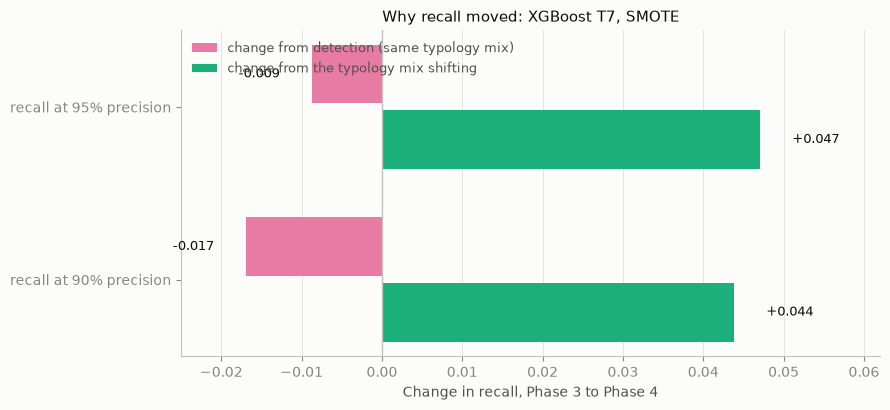

In [6]:
chosen = f"xgb_t7_{CHOSEN}"
panel = mix[(mix["model"] == chosen)].set_index("precision_target")
fig, axis = plt.subplots(figsize=(9, 4.2))
targets = list(panel.index)
base = np.arange(len(targets))
axis.barh(base + 0.19, panel["change_from_detection"], height=0.34, color=COLOUR["xgb_t0_smote"], label="change from detection (same typology mix)")
axis.barh(base - 0.19, panel["change_from_typology_mix"], height=0.34, color=COLOUR["xgb_t7_smote"], label="change from the typology mix shifting")
axis.axvline(0, color=BASELINE, linewidth=1)
for y, value in zip(base + 0.19, panel["change_from_detection"]):
    axis.text(value - 0.004, y, f"{value:+.3f}", va="center", ha="right", fontsize=9, color=INK)
for y, value in zip(base - 0.19, panel["change_from_typology_mix"]):
    axis.text(value + 0.004, y, f"{value:+.3f}", va="center", fontsize=9, color=INK)
axis.set_yticks(base, [f"recall at {t:.0%} precision" for t in targets])
axis.set(xlabel="Change in recall, Phase 3 to Phase 4", title=f"Why recall moved: {SHORT[chosen]}",
         xlim=(-0.025, 0.062))
axis.grid(axis="y", visible=False)
axis.legend(loc="upper left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "mix_decomposition.png", dpi=120)
plt.show()

## How much of this is just a different random dataset?

The same fixed model, over the first repeat's folds, run on seeds 42, 7 and 101
under both the pre-fix and post-fix generators. The spread across seeds within
one version is realisation noise; the shift between versions at matched seeds is
what the fixes did.

In [7]:
control = pd.concat([
    pd.read_csv(OUT / "realisation_control_prefix.csv"),
    pd.read_csv(OUT / "realisation_control_postfix.csv"),
])
control_by_seed = control.groupby(["generator_version", "seed"])["pr_auc"].mean().unstack(0).round(4)
control_by_seed["post_minus_pre"] = (control_by_seed["postfix"] - control_by_seed["prefix"]).round(4)
display(control_by_seed)
display(control.groupby("generator_version")["pr_auc"].agg(["mean", "std"]).round(4))
print(f"matched-seed effect of the fixes: mean {control_by_seed['post_minus_pre'].mean():+.4f}")
print(f"seed-to-seed spread within a version: {control.groupby(['generator_version', 'seed'])['pr_auc'].mean().groupby('generator_version').std().mean():.4f}")

generator_version,postfix,prefix,post_minus_pre
seed,,,
7,0.7223,0.7550,-0.0327
42,0.7812,0.7622,0.0190
101,0.7197,0.7499,-0.0302


,mean,std
generator_version,,
postfix,0.7411,0.0502
prefix,0.7557,0.0494


matched-seed effect of the fixes: mean -0.0146
seed-to-seed spread within a version: 0.0205


## The lookalike audit after the fixes

Every typology, every feature: the tail holding a quarter of that typology's
rows, and the share of legitimate rows in the same region. Under 1% is flagged.

In [8]:
audit = pd.read_csv(OUT / "lookalike_audit.csv")
flagged = audit[audit["flagged_no_counterpart"]]
print(f"{len(flagged)} signature(s) flagged after the fixes")
display(audit.head(8)[["typology", "feature", "direction", "typology_share_in_region",
                       "legitimate_share_in_region", "fraud_purity_of_region", "legitimate_counterpart"]].round(4))
baseline_audit = pd.read_csv(OUT / "phase3_baseline" / "lookalike_audit.csv")
print("the two Phase 3 flags, before and after:")
keys = ["job_acceptance_latency_seconds", "submission_latency_seconds"]
before_rows = baseline_audit[(baseline_audit.typology == "payout_gaming") & baseline_audit.feature.isin(keys)]
after_rows = audit[(audit.typology == "payout_gaming") & audit.feature.isin(keys)]
display(before_rows.merge(after_rows, on=["typology", "feature"], suffixes=("_before", "_after"))[
    ["feature", "legitimate_share_in_region_before", "legitimate_share_in_region_after",
     "fraud_purity_of_region_before", "fraud_purity_of_region_after"]].round(5))

1 signature(s) flagged after the fixes


,typology,feature,direction,typology_share_in_region,legitimate_share_in_region,fraud_purity_of_region,legitimate_counterpart
0,sim_farming,device_shared_agent_count_30d,upper tail,0.2573,0.0100,0.4837,device_sharing_team_share (honest team sharing...
1,sim_farming,agent_activation_velocity_24h,upper tail,0.2717,0.0206,0.4445,campaign and market day volume multipliers
2,payout_gaming,job_acceptance_latency_seconds,upper tail,0.2502,0.0223,0.1447,batch_acceptance (honest agents who accept job...
3,payout_gaming,submission_latency_seconds,upper tail,0.2502,0.0295,0.1154,fast_submission_latency_minutes (honest queue ...
4,sim_farming,agent_activation_velocity_1h,upper tail,0.2731,0.0310,0.3375,burst_intra_day_spread_hours (campaign and mar...
5,ghost,complaint_or_refund_flag_7d,flag == 1,0.0774,0.0323,0.0881,legit_behaviour.complaint_daily_prob
6,payout_gaming,complaint_or_refund_flag_7d,flag == 1,0.0382,0.0323,0.0881,legit_behaviour.complaint_daily_prob
7,sim_farming,device_activations_7d,upper tail,0.2507,0.0332,0.3348,device_sharing_team_share (honest team sharing...


the two Phase 3 flags, before and after:


,feature,legitimate_share_in_region_before,legitimate_share_in_region_after,fraud_purity_of_region_before,fraud_purity_of_region_after
0,job_acceptance_latency_seconds,0.00011,0.02234,0.96842,0.14468
1,submission_latency_seconds,0.00019,0.02953,0.94520,0.11536


## Is collusion genuinely hard?

Collusion is designed to hide inside the legitimate trial-then-lapse population.
On the customer channels that define the typology the two are nearly the same
distribution, so its low recall is a property of the problem rather than an
omission.

In [9]:
overlap = pd.read_csv(OUT / "collusion_overlap.csv")
display(overlap[["feature", "group", "auc_vs_trial_lapse", "overlap_vs_trial_lapse",
                 "auc_vs_all_legitimate", "collusion_median", "trial_lapse_median"]].round(3))
separability = pd.read_csv(OUT / "collusion_separability_by_fold.csv")
display(separability.groupby("feature_set")["roc_auc"].agg(["mean", "std"]).round(4))

,feature,group,auc_vs_trial_lapse,overlap_vs_trial_lapse,auc_vs_all_legitimate,collusion_median,trial_lapse_median
0,agent_activation_velocity_24h,agent history,0.758,0.621,0.756,6.000,2.000
1,device_activations_7d,agent history,0.750,0.627,0.745,23.000,11.000
2,agent_tenure_days,agent history,0.686,0.681,0.683,234.435,353.635
3,days_to_payout_cutoff,activation or customer,0.655,0.693,0.658,2.321,6.099
4,agent_activation_velocity_1h,agent history,0.644,0.773,0.639,2.000,1.000
5,customer_active_days_7d,activation or customer,0.590,0.846,0.738,1.000,0.000
6,usage_minutes_total_7d,activation or customer,0.590,0.862,0.714,1.329,0.000
7,transaction_count_7d,activation or customer,0.582,0.869,0.699,0.000,0.000
8,topup_amount_total_7d,activation or customer,0.566,0.919,0.673,0.000,0.000
9,days_to_first_customer_activity,activation or customer,0.561,0.882,0.605,1.000,8.000


,mean,std
feature_set,,
activation_and_customer_only,0.6980,0.0493
all_features,0.8175,0.0607


# The current results, in full

Everything below is the post-fix run. The evaluation design, folds, repeats,
models and metrics are unchanged from Phase 3; only the generator changed.

# Model results: the evaluation

Every number in this notebook is read from the CSV files under `outputs/`,
written by `python -m src.train.run` and `python -m src.eval.investigations`.
Nothing here trains a model.

**Evaluation design.** Repeated grouped, time-ordered cross-validation (`config/model.yaml`):

- **Folds and repeats.** 5 folds, repeated 3 times with a fresh agent grouping each time, giving 15 folds. Agents are assigned to folds by `StratifiedGroupKFold`, so no agent is ever split across folds.
- **Test rows.** Each fold's test set is its 70 agents' activations submitted on or after day 90.
- **Training rows.** Training uses the other agents' activations whose 8-day downstream window (days 0 to 7) had closed by day 90, so no training row carries a T7 feature or label observed during the test period.
- **Hyperparameter search.** A 12-candidate random search runs on an inner validation fold carved out of the training data under the same grouped, time-ordered rules. The outer test rows are never seen during search.
- **Resampling.** SMOTE is applied to training rows only, after splitting. A test intercepts every SMOTE call to check this.

**Models.**

- Four hand-written analyst rules, with no fitting.
- Logistic regression on the T7 feature set.
- XGBoost on the T7 feature set.
- XGBoost on the T0 feature set only.

"T7 feature set" means everything available seven days after submission: the 18 T0 features plus the 9 downstream features. Both XGBoost models are run with SMOTE and with `scale_pos_weight`, on the same folds.

**Reporting.** PR-AUC is the headline. Recall at 90% and 95% precision is the recall at the best threshold on that fold reaching that precision; it is a metric definition, not a decision threshold. Every metric is a mean with its standard deviation across the 15 folds, and every fold's prevalence is shown beside its scores. No calibration or decision-band work is done here.

## The folds

One row per fold. `test_prevalence` differs between folds, so PR-AUC values are
only comparable alongside it. Each fold holds 70 test agents, of whom 3 to 5 are
systematic, which is why the spread across folds matters.

In [10]:
fold_view = cv_folds.copy()
fold_view.round(4)

,repeat,fold,n_train,train_prevalence,n_inner_train,n_inner_val,inner_val_positives,n_test,test_positives,test_prevalence,n_test_agents,test_agents_honest,test_agents_opportunistic,test_agents_systematic,test_positives_sim_farming,test_positives_ghost,test_positives_collusion,test_positives_payout_gaming
0,0,0,34371,0.0738,13276,3453,271,9112,828,0.0909,70,52,14,4,374,193,173,88
1,0,1,34235,0.0706,13215,3409,234,8907,619,0.0695,70,50,17,3,228,189,88,114
2,0,2,34303,0.0698,13277,3439,223,8957,615,0.0687,70,52,14,4,302,135,58,120
3,0,3,34184,0.0697,13229,3438,269,8948,675,0.0754,70,60,6,4,377,89,89,120
4,0,4,34163,0.0721,13158,3469,293,8895,717,0.0806,70,59,8,3,317,107,170,123
5,1,0,34313,0.0749,13262,3409,246,9006,797,0.0885,70,48,19,3,320,196,190,91
6,1,1,34259,0.0701,13333,3414,204,8994,676,0.0752,70,53,13,4,280,200,82,114
7,1,2,34262,0.0699,13164,3430,287,8923,623,0.0698,70,51,15,4,301,128,75,119
8,1,3,34199,0.0696,13174,3412,240,8933,660,0.0739,70,61,5,4,380,83,69,128
9,1,4,34223,0.0716,13305,3562,301,8963,698,0.0779,70,60,7,3,317,106,162,113


## Results table

Mean (standard deviation) across 15 folds. The prevalence column is the test
prevalence, the PR-AUC a random ranking would score.

In [11]:
formatted

,model,description,n_folds,prevalence,pr_auc,roc_auc,recall_at_p90,recall_at_p95
0,rules_t7,"Rules baseline (4 analyst rules, T7 time)",15,0.077 (0.007),0.388 (0.032),0.797 (0.025),0.102 (0.091),0.012 (0.013)
1,logreg_t7,"Logistic regression, T7 feature set",15,0.077 (0.007),0.703 (0.034),0.931 (0.012),0.364 (0.052),0.234 (0.066)
2,xgb_t7_smote,"XGBoost, T7 feature set, SMOTE",15,0.077 (0.007),0.781 (0.035),0.948 (0.011),0.535 (0.056),0.470 (0.059)
3,xgb_t7_spw,"XGBoost, T7 feature set, scale_pos_weight",15,0.077 (0.007),0.766 (0.037),0.944 (0.012),0.514 (0.065),0.439 (0.062)
4,xgb_t0_smote,"XGBoost, T0 feature set only, SMOTE",15,0.077 (0.007),0.711 (0.051),0.923 (0.020),0.453 (0.080),0.400 (0.076)
5,xgb_t0_spw,"XGBoost, T0 feature set only, scale_pos_weight",15,0.077 (0.007),0.690 (0.048),0.917 (0.019),0.419 (0.077),0.368 (0.073)


PR-AUC for every model in every fold, with that fold's prevalence and
number of systematic test agents.

In [12]:
pr_by_fold = fold_metrics.pivot_table(index=["repeat", "fold"], columns="model", values="pr_auc")[MODEL_ORDER]
pr_by_fold.insert(0, "test_prevalence", fold_metrics.groupby(["repeat", "fold"])["prevalence"].first())
pr_by_fold.insert(1, "test_agents_systematic", fold_metrics.groupby(["repeat", "fold"])["test_agents_systematic"].first())
pr_by_fold.round(3)

model        test_prevalence  test_agents_systematic  rules_t7  logreg_t7  xgb_t7_smote  xgb_t7_spw  xgb_t0_smote  xgb_t0_spw
repeat fold                                                                                                                  
0      0               0.091                       4     0.406      0.713         0.779       0.756         0.691       0.655
       1               0.069                       3     0.357      0.636         0.719       0.706         0.635       0.582
       2               0.069                       4     0.350      0.714         0.790       0.764         0.719       0.677
       3               0.075                       4     0.428      0.722         0.823       0.818         0.765       0.718
       4               0.081                       3     0.398      0.724         0.788       0.763         0.739       0.727
1      0               0.088                       3     0.382      0.681         0.744       0.738         0.632       0.638
       1               0.075                       4     0.393      0.685         0.757       0.736         0.696       0.675
       2               0.070                       4     0.347      0.692         0.778       0.777         0.700       0.699
       3               0.074                       4     0.425      0.731         0.833       0.813         0.780       0.753
       4               0.078                       3     0.399      0.728         0.793       0.766         0.751       0.714
2      0               0.088                       4     0.430      0.724         0.793       0.785         0.709       0.719
       1               0.075                       4     0.393      0.689         0.765       0.744         0.707       0.681
       2               0.074                       4     0.319      0.635         0.726       0.712         0.622       0.627
       3               0.068                       3     0.394      0.751         0.833       0.835         0.778       0.750
       4               0.080                       3     0.404      0.729         0.794       0.776         0.746       0.729

## Headline metrics

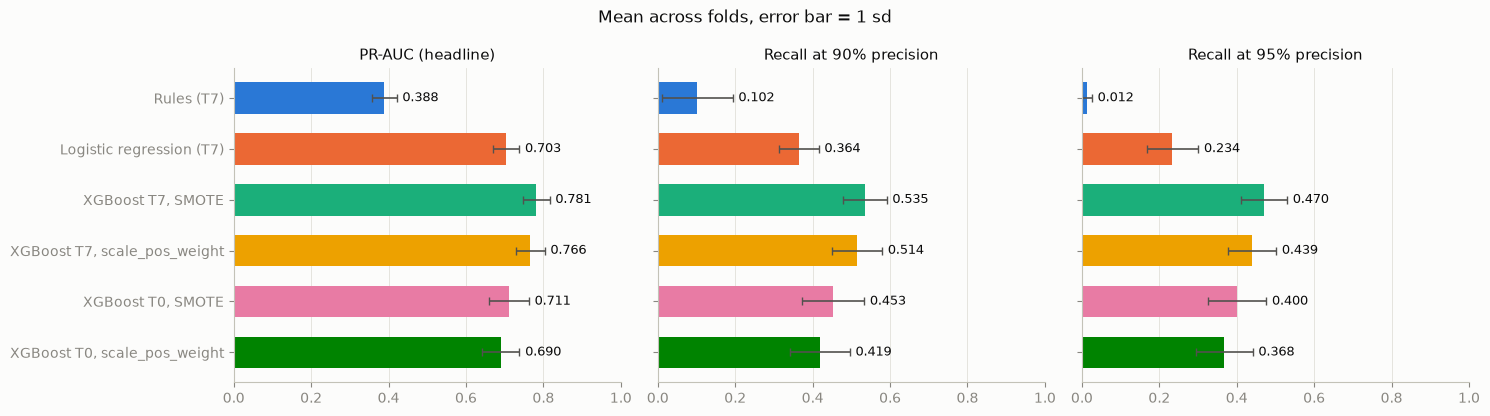

In [13]:
metrics = [("pr_auc", "PR-AUC (headline)"), ("recall_at_p90", "Recall at 90% precision"), ("recall_at_p95", "Recall at 95% precision")]
ordered = summary.set_index("model").loc[MODEL_ORDER]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
positions = np.arange(len(MODEL_ORDER))[::-1]
for axis, (metric, title) in zip(axes, metrics):
    axis.barh(positions, ordered[f"{metric}_mean"], height=0.62, color=[COLOUR[m] for m in MODEL_ORDER],
              xerr=ordered[f"{metric}_sd"], error_kw={"ecolor": INK_2, "elinewidth": 1.2, "capsize": 3})
    for y, mean, sd in zip(positions, ordered[f"{metric}_mean"], ordered[f"{metric}_sd"]):
        axis.text(mean + sd + 0.015, y, f"{mean:.3f}", va="center", fontsize=9, color=INK)
    axis.set(xlim=(0, 1), title=title)
    axis.grid(axis="y", visible=False)
axes[0].set_yticks(positions, [SHORT[m] for m in MODEL_ORDER])
fig.suptitle("Mean across folds, error bar = 1 sd", color=INK, fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / "metric_summary.png", dpi=120)
plt.show()

## Precision-recall curves

Interpolated precision (the best precision reachable at that recall or higher)
on a common recall grid, averaged across the 15 folds. The shaded band is one
standard deviation across folds.

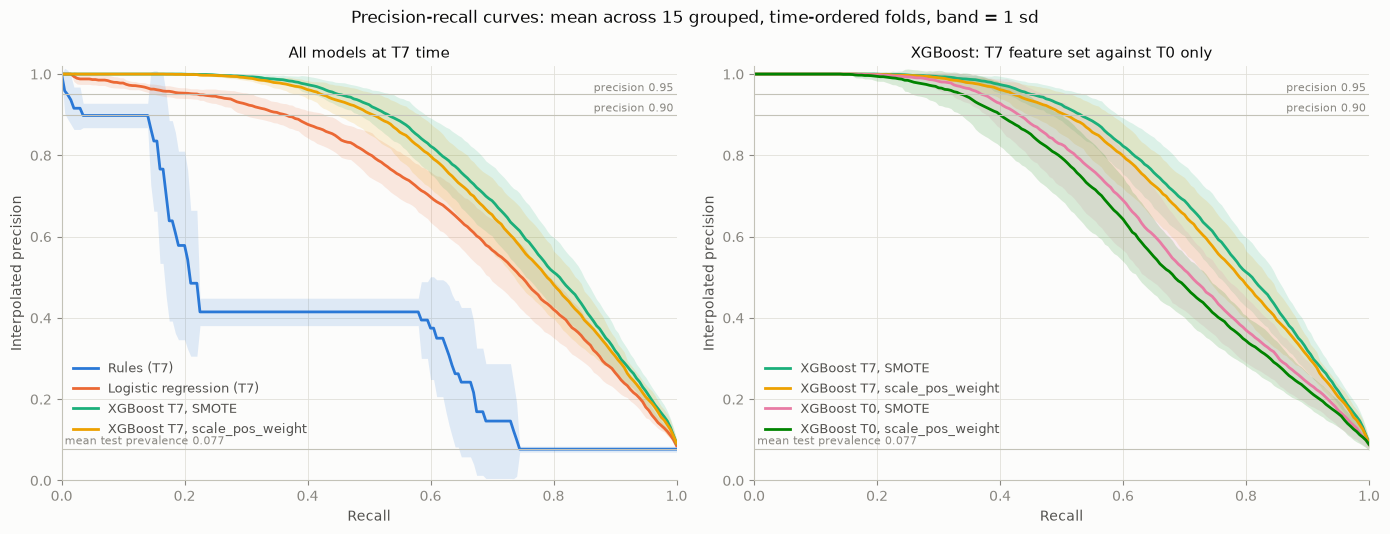

In [14]:
RECALL_GRID = np.linspace(0.0, 1.0, 201)


def interpolated_precision(labels: np.ndarray, scores: np.ndarray) -> np.ndarray:
    """Highest precision achievable at recall of at least r, on a fixed recall grid."""
    precision, recall, _ = precision_recall_curve(labels, scores)
    order = np.argsort(recall, kind="stable")
    recall, precision = recall[order], precision[order]
    best_from_here = np.maximum.accumulate(precision[::-1])[::-1]
    index = np.clip(np.searchsorted(recall, RECALL_GRID, side="left"), 0, len(recall) - 1)
    return best_from_here[index]


curves = {}
for (model, repeat, fold), group in predictions.groupby(["model", "repeat", "fold"]):
    curves.setdefault(model, []).append(
        interpolated_precision(group["label"].to_numpy(), group["score"].to_numpy(dtype=float))
    )
curve_mean = {m: np.mean(c, axis=0) for m, c in curves.items()}
curve_sd = {m: np.std(c, axis=0, ddof=1) for m, c in curves.items()}
mean_prevalence = fold_metrics.groupby(["repeat", "fold"])["prevalence"].first().mean()


def draw_curves(axis, models, title):
    for model in models:
        axis.fill_between(RECALL_GRID, curve_mean[model] - curve_sd[model],
                          curve_mean[model] + curve_sd[model], color=COLOUR[model], alpha=0.14, linewidth=0)
        axis.plot(RECALL_GRID, curve_mean[model], color=COLOUR[model], label=SHORT[model])
    for level in (0.90, 0.95):
        axis.axhline(level, color=BASELINE, linewidth=0.8)
        axis.text(0.995, level + 0.008, f"precision {level:.2f}", color=MUTED, fontsize=8, ha="right")
    axis.axhline(mean_prevalence, color=BASELINE, linewidth=0.8)
    axis.text(0.005, mean_prevalence + 0.012, f"mean test prevalence {mean_prevalence:.3f}", color=MUTED, fontsize=8)
    axis.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Recall", ylabel="Interpolated precision", title=title)
    axis.legend(loc="lower left", bbox_to_anchor=(0.0, 0.08), fontsize=9)


fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
draw_curves(axes[0], ["rules_t7", "logreg_t7", "xgb_t7_smote", "xgb_t7_spw"], "All models at T7 time")
draw_curves(axes[1], ["xgb_t7_smote", "xgb_t7_spw", "xgb_t0_smote", "xgb_t0_spw"], "XGBoost: T7 feature set against T0 only")
fig.suptitle("Precision-recall curves: mean across 15 grouped, time-ordered folds, band = 1 sd", color=INK, fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / "pr_curves.png", dpi=120)
plt.show()

## Resampling compared at matched strength

The Phase 3 comparison was not interpretable: SMOTE oversampled to a minority
ratio of 0.30 (about 4x) while scale_pos_weight weighted to full balance (about
14x). Here every method runs at every effective ratio, plus a "none" arm that
leaves the training split untouched. Hyperparameters are chosen once per fold by
an inner search using **no class handling at all**, then held fixed across every
cell, so neither method inherits a search tuned to its own conditions.

**Three findings, and the Phase 3 conclusion does not survive.**

1. **At matched strength the methods are indistinguishable.** At a ratio of 0.1, SMOTE scores 0.7803 and scale_pos_weight 0.7795; at 1.0, 0.7684 against 0.7647. Every gap is under 0.004, against a fold-to-fold standard deviation of 0.037. The Phase 3 result ("SMOTE beats scale_pos_weight in 14 of 15 folds") compared SMOTE at 0.30 with weighting at 1.0: it measured the difference in **strength**, not in method.
2. **Strength is what matters, and less is better, monotonically.** Both methods fall steadily as the minority is pushed up: 0.780 at 0.1 down to 0.765 at 1.0. **Doing nothing at all scores best of any cell** (0.7807, recall at 90% precision 0.546).
3. **Fixing SMOTE's fractional flags makes it worse, not better.** SMOTE-NC, which copies binary columns from the neighbourhood majority instead of interpolating them, is below plain SMOTE at every ratio and collapses as strength rises (0.743 at ratio 1.0 against 0.768). So the "SMOTE invents impossible rows" objection, though true, is not what was costing performance.

**Which I would use: none, or scale_pos_weight at a low ratio.** The headline
metric is threshold-free ranking, and ranking gains nothing from rebalancing; on
this dataset every intervention costs a little and heavy ones cost more. This
recommendation is recorded but **not applied**: the models reported elsewhere in
this notebook still use the Phase 3 configuration, so that the before-and-after
comparison changes one thing at a time. Imbalance handling should be revisited
when calibration and decision bands are on the table, since those depend on the
predicted probabilities rather than on their order.

In [15]:
sweep = pd.read_csv(OUT / "resampling_sweep_summary.csv")
display(sweep.pivot(index="ratio_label", columns="method", values="pr_auc_mean").round(4))
sweep[["method", "ratio_label", "n_folds", "mean_minority_ratio", "pr_auc_mean", "pr_auc_sd",
       "recall_at_p90_mean", "recall_at_p95_mean"]].round(4)

method,none,scale_pos_weight,smote,smotenc
ratio_label,,,,
0.1,NaN,0.7795,0.7803,0.7782
0.2,NaN,0.7767,0.7780,0.7709
0.3,NaN,0.7745,0.7778,0.7671
0.5,NaN,0.7703,0.7733,0.7576
1,NaN,0.7647,0.7684,0.7427
natural,0.7807,NaN,NaN,NaN


,method,ratio_label,n_folds,mean_minority_ratio,pr_auc_mean,pr_auc_sd,recall_at_p90_mean,recall_at_p95_mean
0,none,natural,15,0.0767,0.7807,0.0380,0.5464,0.4766
1,scale_pos_weight,0.1,15,0.1000,0.7795,0.0373,0.5413,0.4722
2,scale_pos_weight,0.2,15,0.2000,0.7767,0.0369,0.5399,0.4654
3,scale_pos_weight,0.3,15,0.3000,0.7745,0.0370,0.5323,0.4576
4,scale_pos_weight,0.5,15,0.5000,0.7703,0.0369,0.5244,0.4485
5,scale_pos_weight,1,15,1.0000,0.7647,0.0364,0.5112,0.4364
6,smote,0.1,15,0.1000,0.7803,0.0370,0.5436,0.4726
7,smote,0.2,15,0.2000,0.7780,0.0370,0.5392,0.4732
8,smote,0.3,15,0.3000,0.7778,0.0359,0.5281,0.4630
9,smote,0.5,15,0.5000,0.7733,0.0370,0.5232,0.4576


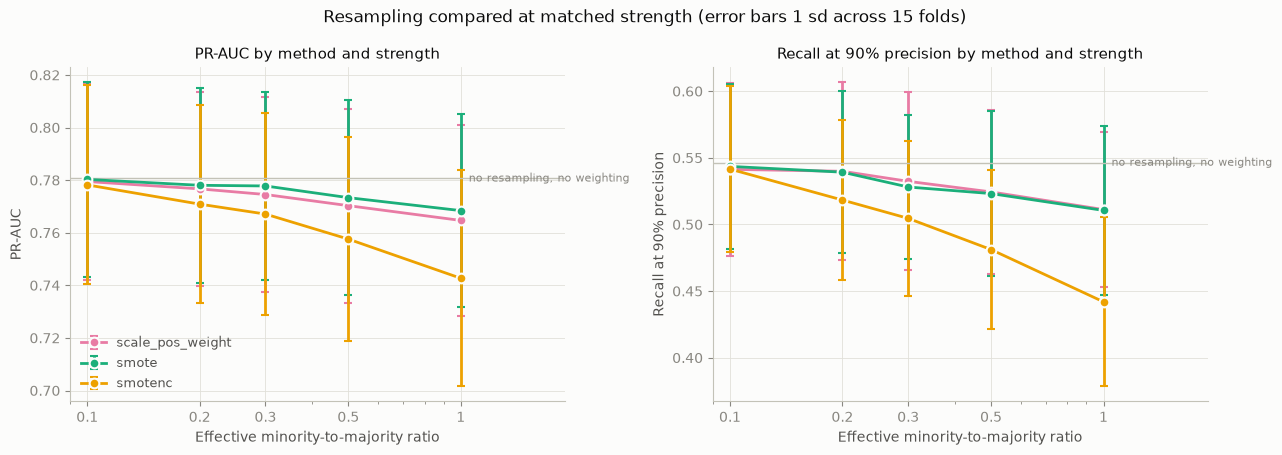

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
method_colour = {"smote": COLOUR["xgb_t7_smote"], "smotenc": COLOUR["xgb_t7_spw"], "scale_pos_weight": COLOUR["xgb_t0_smote"]}
ticks = sorted(sweep.loc[sweep["method"] != "none", "mean_minority_ratio"].unique())
for axis, (metric, title) in zip(axes, [("pr_auc", "PR-AUC"), ("recall_at_p90", "Recall at 90% precision")]):
    for method, group in sweep[sweep["method"] != "none"].groupby("method"):
        group = group.sort_values("mean_minority_ratio")
        axis.errorbar(group["mean_minority_ratio"], group[f"{metric}_mean"], yerr=group[f"{metric}_sd"],
                      color=method_colour[method], marker="o", markersize=7, capsize=3,
                      markeredgecolor=SURFACE, markeredgewidth=1.5, label=method)
    none_row = sweep[sweep["method"] == "none"].iloc[0]
    axis.axhline(none_row[f"{metric}_mean"], color=BASELINE, linewidth=1)
    axis.text(1.0, none_row[f"{metric}_mean"], "  no resampling, no weighting", color=MUTED,
              fontsize=8, va="center", ha="left")
    axis.set_xlim(0.09, 1.9)
    axis.set(xlabel="Effective minority-to-majority ratio", ylabel=title,
             title=f"{title} by method and strength", xscale="log")
    axis.set_xticks(ticks, [f"{r:g}" for r in ticks])
axes[0].legend(fontsize=9, loc="lower left")
fig.suptitle("Resampling compared at matched strength (error bars 1 sd across 15 folds)", color=INK, fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / "resampling_sweep.png", dpi=120)
plt.show()

### The unmatched Phase 3 comparison, for reference

These are the two headline models as configured in Phase 3: SMOTE at a minority
ratio of 0.30 against `scale_pos_weight` at full balance. SMOTE still wins here,
by 0.015 PR-AUC on the T7 set. The sweep above shows why that gap is not
evidence about SMOTE: at matched strength the two methods are indistinguishable,
and the apparent advantage was the difference in strength.

In [17]:
paired.set_index("comparison").round(4).T

comparison,T7: scale_pos_weight minus SMOTE,T0: scale_pos_weight minus SMOTE,SMOTE: T7 minus T0,scale_pos_weight: T7 minus T0
n_folds,15.0000,15.0000,15.0000,15.0000
pr_auc_diff_mean,-0.0149,-0.0217,0.0697,0.0765
pr_auc_diff_sd,0.0096,0.0200,0.0210,0.0242
pr_auc_folds_first_better,1.0000,3.0000,15.0000,15.0000
roc_auc_diff_mean,-0.0044,-0.0064,0.0254,0.0274
roc_auc_diff_sd,0.0039,0.0062,0.0100,0.0111
roc_auc_folds_first_better,2.0000,2.0000,15.0000,15.0000
recall_at_p90_diff_mean,-0.0207,-0.0343,0.0823,0.0959
recall_at_p90_diff_sd,0.0264,0.0343,0.0324,0.0331
recall_at_p90_folds_first_better,4.0000,3.0000,15.0000,15.0000


## T0 against T7: the escrow hold window

Stated plainly, and more strongly than in Phase 3: **XGBoost on T0 features
alone already achieves most of the ranking performance.** With SMOTE, T0 scores
PR-AUC 0.711 (sd 0.051) against 0.781 (sd 0.035) for the T7 feature set, which
is **91%** of the T7 value from information available the moment an activation
is submitted. T0 alone now also beats logistic regression using every T7 feature
(0.704).

**The gap narrowed after the fixes, from 0.081 to 0.070.** That cuts against the
hold-window argument rather than supporting it, and it is consistent with the
typology mix: sim farming, the typology most detectable at T0, is a larger share
of fraud in this dataset.

- **Every fold.** T7 still beats T0 in all 15 folds, by 0.070 PR-AUC (sd 0.021).
- **Recall at 90% precision.** 0.453 at T0 against 0.535 at T7.
- **Where the gain comes from.** Almost entirely ghost activations, whose recall
  doubles from 0.185 at T0 to 0.368 at T7. Sim farming gains 0.053 and payout
  gaming 0.025; collusion gains 0.084 from a very low base.

Whether a 0.07 PR-AUC gain justifies holding every payout for seven days is a
business judgement this notebook cannot make. The result does not support a
claim that the hold window is essential for detection overall. It supports a
narrower claim: the hold window is what makes ghost activations detectable.

Each point in the scatter below is one fold. A point above the diagonal is a
fold where T7 beat T0.

In [18]:
comparison = summary.set_index("model").loc[
    ["xgb_t7_smote", "xgb_t0_smote", "xgb_t7_spw", "xgb_t0_spw"],
    ["pr_auc_mean", "pr_auc_sd", "recall_at_p90_mean", "recall_at_p90_sd", "recall_at_p95_mean", "recall_at_p95_sd"],
]
comparison.round(3)

,pr_auc_mean,pr_auc_sd,recall_at_p90_mean,recall_at_p90_sd,recall_at_p95_mean,recall_at_p95_sd
model,,,,,,
xgb_t7_smote,0.781,0.035,0.535,0.056,0.470,0.059
xgb_t0_smote,0.711,0.051,0.453,0.080,0.400,0.076
xgb_t7_spw,0.766,0.037,0.514,0.065,0.439,0.062
xgb_t0_spw,0.690,0.048,0.419,0.077,0.368,0.073


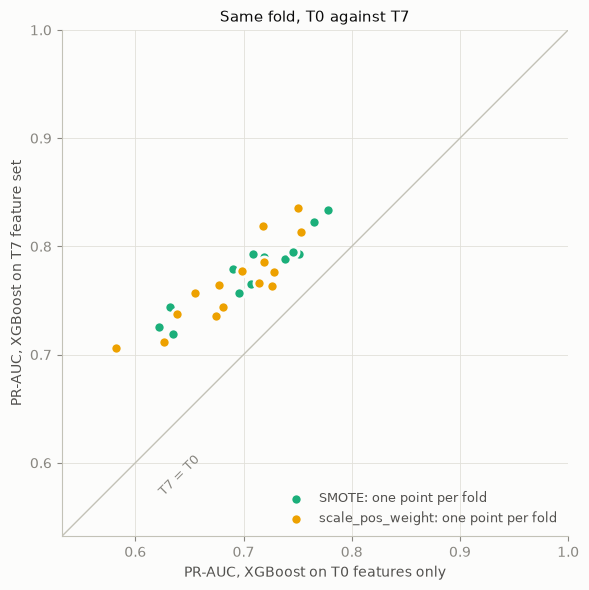

In [19]:
fig, axis = plt.subplots(figsize=(6.2, 6))
indexed = fold_metrics.set_index(["model", "repeat", "fold"])["pr_auc"]
for method, t7_model, t0_model in (("SMOTE", "xgb_t7_smote", "xgb_t0_smote"), ("scale_pos_weight", "xgb_t7_spw", "xgb_t0_spw")):
    axis.scatter(indexed.loc[t0_model], indexed.loc[t7_model], s=64, color=COLOUR[t7_model],
                 edgecolor=SURFACE, linewidth=2, label=f"{method}: one point per fold", zorder=3)
axis.plot([0, 1], [0, 1], color=BASELINE, linewidth=1)
axis.text(0.62, 0.57, "T7 = T0", color=MUTED, fontsize=9, rotation=45)
low = min(indexed.loc[["xgb_t0_smote", "xgb_t0_spw"]].min(), indexed.loc[["xgb_t7_smote", "xgb_t7_spw"]].min()) - 0.05
axis.set(xlim=(max(low, 0), 1), ylim=(max(low, 0), 1), xlabel="PR-AUC, XGBoost on T0 features only",
         ylabel="PR-AUC, XGBoost on T7 feature set", title="Same fold, T0 against T7")
axis.set_aspect("equal")
axis.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "t0_vs_t7_by_fold.png", dpi=120)
plt.show()

## Per-typology recall (chosen model)

Recall within each fraud typology at the fold's overall 90% and 95% precision
operating points, for XGBoost with SMOTE on the T7 set and its T0-only
counterpart. `n_positive_min` is the fewest positives of that typology in any
single test fold; collusion drops to 51, so its per-fold recall is the noisiest
number here.

- **Sim farming** is caught best: recall 0.83 at 90% precision, and already 0.78 at T0, from device sharing, velocity, network and SIM-age signals.
- **Ghost** activations depend on the hold window: recall 0.19 at T0 and 0.37 at T7.
- **Payout gaming** fell from 0.43 to 0.29 once its held-job signature gained an honest counterpart. This is the intended consequence of the Phase 4 fix, and the number to trust: the Phase 3 value was inflated by a defect.
- **Collusion** remains close to undetected: 0.12 recall at 90% precision with T7, 0.04 at T0. The customer is real, the submission is ordinary, and the downstream drop-off overlaps genuine trial-then-lapse customers by design (see the collusion check above).

In [20]:
typology_view = typology[typology["model"].isin(["xgb_t7_" + CHOSEN, "xgb_t0_" + CHOSEN])]
typology_view.pivot_table(
    index=["precision_target", "typology"], columns="model",
    values=["recall_mean", "recall_sd", "n_positive_mean", "n_positive_min"],
).round(3)

n_positive_mean              n_positive_min               recall_mean                 recall_sd             
model                             xgb_t0_smote xgb_t7_smote   xgb_t0_smote xgb_t7_smote xgb_t0_smote xgb_t7_smote xgb_t0_smote xgb_t7_smote
precision_target typology                                                                                                                  
0.90             collusion               115.6        115.6           58.0         58.0        0.039        0.123        0.041        0.089
                 ghost                   142.6        142.6           83.0         83.0        0.185        0.368        0.046        0.033
                 payout_gaming           113.0        113.0           79.0         79.0        0.260        0.285        0.080        0.070
                 sim_farming             319.6        319.6          228.0        228.0        0.779        0.832        0.060        0.025
0.95             collusion               115.6        115.6           58.0         58.0        0.018        0.066        0.020        0.062
                 ghost                   142.6        142.6           83.0         83.0        0.129        0.275        0.043        0.029
                 payout_gaming           113.0        113.0           79.0         79.0        0.199        0.223        0.082        0.065
                 sim_farming             319.6        319.6          228.0        228.0        0.723        0.779        0.057        0.035

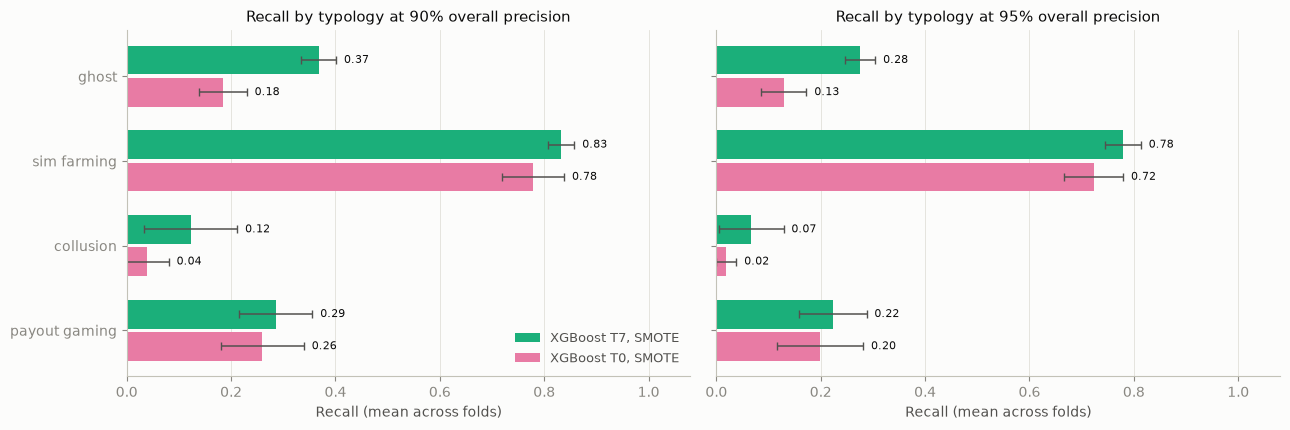

In [21]:
typologies = ["ghost", "sim_farming", "collusion", "payout_gaming"]
models = ["xgb_t7_" + CHOSEN, "xgb_t0_" + CHOSEN]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for axis, target in zip(axes, (0.90, 0.95)):
    subset = typology[(typology["precision_target"] == target)].set_index(["model", "typology"])
    base = np.arange(len(typologies))[::-1]
    for offset, model in zip((0.19, -0.19), models):
        rows = subset.loc[model].reindex(typologies)
        axis.barh(base + offset, rows["recall_mean"], height=0.34, color=COLOUR[model], label=SHORT[model],
                  xerr=rows["recall_sd"], error_kw={"ecolor": INK_2, "elinewidth": 1.1, "capsize": 3})
        for y, mean, sd in zip(base + offset, rows["recall_mean"], rows["recall_sd"]):
            axis.text(mean + sd + 0.015, y, f"{mean:.2f}", va="center", fontsize=8, color=INK)
    axis.set(xlim=(0, 1.08), title=f"Recall by typology at {target:.0%} overall precision", xlabel="Recall (mean across folds)")
    axis.grid(axis="y", visible=False)
axes[0].set_yticks(np.arange(len(typologies))[::-1], [t.replace("_", " ") for t in typologies])
axes[0].legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "typology_recall.png", dpi=120)
plt.show()

## Per-typology recall, before and after

Payout gaming is the typology the fixes targeted, and it falls by 0.147 at 90%
precision (0.433 to 0.285), the largest single move in the table. Sim farming
and collusion rise, ghost is roughly flat.

In [22]:
view = before_after["typology_recall"]
view = view[(view["model"] == f"xgb_t7_{CHOSEN}")]
view[["precision_target", "typology", "recall_mean_before", "recall_mean_after", "recall_mean_change",
      "n_positive_mean_before", "n_positive_mean_after"]].round(3)

,precision_target,typology,recall_mean_before,recall_mean_after,recall_mean_change,n_positive_mean_before,n_positive_mean_after
32,0.90,collusion,0.077,0.123,0.046,99.6,115.6
33,0.90,ghost,0.402,0.368,-0.034,189.8,142.6
34,0.90,payout_gaming,0.433,0.285,-0.147,140.4,113.0
35,0.90,sim_farming,0.787,0.832,0.045,247.4,319.6
36,0.95,collusion,0.035,0.066,0.031,99.6,115.6
37,0.95,ghost,0.305,0.275,-0.030,189.8,142.6
38,0.95,payout_gaming,0.356,0.223,-0.134,140.4,113.0
39,0.95,sim_farming,0.717,0.779,0.062,247.4,319.6


Mean recall by typology for every model, for reference.

In [23]:
typology.pivot_table(index=["precision_target", "typology"], columns="model", values="recall_mean")[MODEL_ORDER].round(3)

model                           rules_t7  logreg_t7  xgb_t7_smote  xgb_t7_spw  xgb_t0_smote  xgb_t0_spw
precision_target typology                                                                              
0.90             collusion         0.009      0.110         0.123       0.129         0.039       0.048
                 ghost             0.111      0.232         0.368       0.344         0.185       0.182
                 payout_gaming     0.008      0.076         0.285       0.272         0.260       0.209
                 sim_farming       0.171      0.601         0.832       0.800         0.779       0.720
0.95             collusion         0.000      0.055         0.066       0.059         0.018       0.021
                 ghost             0.004      0.112         0.275       0.246         0.129       0.131
                 payout_gaming     0.000      0.031         0.223       0.189         0.199       0.140
                 sim_farming       0.027      0.418         0.779       0.741         0.723       0.669

## How much of the model is the agent rather than the activation?

The chosen model retrained with every agent-history feature removed: tenure,
both velocity windows, device activations, device sharing and distinct devices.
What remains is what the platform can see about this activation and its
customer.

In [24]:
ablation = pd.read_csv(OUT / "agent_history_ablation.csv")
ablation.round(4)

,feature_set,n_features,pr_auc_mean,roc_auc_mean,recall_at_p90_mean,recall_at_p95_mean,pr_auc_sd,roc_auc_sd,recall_at_p90_sd,recall_at_p95_sd
0,t7,27,0.7809,0.9485,0.5352,0.4703,0.0349,0.0109,0.0557,0.0594
1,t7_no_agent_history,21,0.6701,0.8997,0.3943,0.3289,0.0401,0.0176,0.0620,0.0547


## Who pays for a false positive?

Phase 3 reported the composition of false positives. A composition cannot tell
an agent what to expect; a rate can. This is the share of each group's **genuine**
activations that get flagged, so it is the chance that an honest piece of work
has its payout held.

In [25]:
rates = pd.read_csv(OUT / "false_positive_rate_by_honesty.csv")
rates.round(5)

,precision_target,honesty_type,false_positive_rate_mean,false_positive_rate_sd,legitimate_rows_mean,false_positives_mean
0,0.90,honest,0.00108,0.00030,5600.6,6.00000
1,0.90,opportunistic,0.00303,0.00209,1585.8,5.20000
2,0.90,systematic,0.02722,0.00673,1086.6,29.26670
3,0.95,honest,0.00031,0.00023,5600.6,1.73333
4,0.95,opportunistic,0.00144,0.00108,1585.8,2.33333
5,0.95,systematic,0.01173,0.00280,1086.6,12.66670


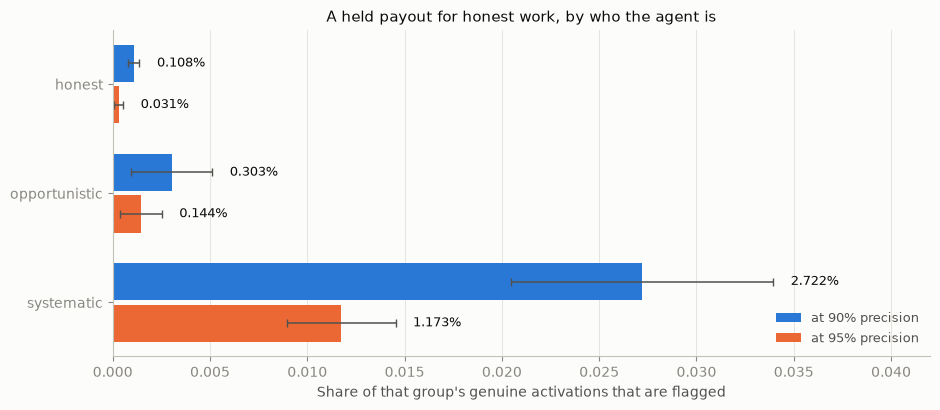

In [26]:
fig, axis = plt.subplots(figsize=(9.5, 4.2))
order = ["honest", "opportunistic", "systematic"]
# Colour encodes the precision level here; the agent type is on the axis.
target_colour = {0.90: "#2a78d6", 0.95: "#eb6834"}
for offset, target in ((0.19, 0.90), (-0.19, 0.95)):
    subset = rates[rates["precision_target"] == target].set_index("honesty_type").reindex(order)
    base = np.arange(len(order))[::-1]
    axis.barh(base + offset, subset["false_positive_rate_mean"], height=0.34,
              color=target_colour[target], xerr=subset["false_positive_rate_sd"],
              error_kw={"ecolor": INK_2, "elinewidth": 1.1, "capsize": 3},
              label=f"at {target:.0%} precision")
    for y, value, sd in zip(base + offset, subset["false_positive_rate_mean"], subset["false_positive_rate_sd"]):
        axis.text(value + sd + 0.0009, y, f"{value:.3%}", va="center", fontsize=9, color=INK)
axis.set_yticks(np.arange(len(order))[::-1], order)
axis.set(xlabel="Share of that group's genuine activations that are flagged",
         title="A held payout for honest work, by who the agent is", xlim=(0, 0.042))
axis.grid(axis="y", visible=False)
axis.legend(fontsize=9, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "false_positive_rates.png", dpi=120)
plt.show()

In [27]:
honest_fp = pd.read_csv(OUT / "investigation_false_positives_on_honest_agents.csv")
honest_fp[honest_fp["precision_target"] == 0.90].round(5)

,model,precision_target,situation,false_positive_rate_mean,false_positive_rate_sd,honest_legitimate_rows_mean
0,xgb_t7_smote,0.9,batch_acceptance,0.00520,0.00453,484.8
1,xgb_t7_smote,0.9,dormant,0.00351,0.00126,1068.0
2,xgb_t7_smote,0.9,shared_device,0.00350,0.00545,324.0
3,xgb_t7_smote,0.9,end_cycle_push,0.00277,0.00098,1395.8
4,xgb_t7_smote,0.9,same_day_sim,0.00232,0.00152,1011.8
5,xgb_t7_smote,0.9,fixed_site,0.00185,0.00294,726.0
6,xgb_t7_smote,0.9,repeat_msisdn,0.00144,0.00301,133.0
7,xgb_t7_smote,0.9,any_situation,0.00128,0.00035,4725.4
8,xgb_t7_smote,0.9,burst_day,0.00117,0.00040,3152.8
9,xgb_t7_smote,0.9,event_backlog,0.00000,0.00000,223.6


### What this means for an escrow system

Characterising the problem, not proposing a fix.

**1. A large part of the score is the agent, not the activation.** Removing the
six agent-history features costs 0.111 PR-AUC (0.781 to 0.670) and 0.141 recall
at 90% precision. Measured against the prevalence floor a random ranking would
achieve (0.077), those features supply about a sixth of the achievable signal.
The remaining model is still far better than chance, so the score is not *only*
an agent-risk score, but a substantial part of it is.

**2. The cost of a false positive is concentrated on a few people.** At the 90%
precision operating point, the share of each group's **genuine** activations
that get flagged is:

| Agent type | Flagged genuine activations | Roughly |
|---|---|---|
| honest | 0.108% | 1 in 925 |
| opportunistic | 0.303% | 1 in 330 |
| systematic | 2.72% | 1 in 37 |

A systematic agent's honest work is held about 25 times more often than an
honest agent's. Two readings, and they conflict:

- *Operationally defensible.* Most wrongly-held payouts belong to people who do defraud elsewhere. The platform is not holding random people's money.
- *Not defensible as a decision about the activation.* Escrow releases a payment for a specific piece of work. When that work is genuine, holding it is a wrong decision regardless of what the agent did last week. The model is scoring the person, and the escrow decision is being made about the job.

**3. Among honest agents, the entire cost falls on the lookalikes.** 1 in 925 is
an average over honest agents, and the average hides the structure completely.
Restricting to genuine activations by agents who never defraud, and splitting by
the honest situations the generator builds in:

| Honest situation | Flagged genuine activations |
|---|---|
| batch acceptance (evening work around another job) | 0.520% |
| genuinely dormant customer | 0.351% |
| shared team enrolment device | 0.350% |
| end-of-cycle push | 0.277% |
| SIM registered the same day | 0.232% |
| fixed-site working | 0.185% |
| **no lookalike situation at all** | **0.000%** |

Across all 15 folds, **not one** honest activation without a lookalike situation
was flagged. Every false positive on an honest agent landed on work that carried
at least one of these patterns. The model is not spreading a small error rate
evenly across honest agents; it is concentrating it entirely on particular
honest working styles.

There is an uncomfortable consequence of the Phase 4 fix in that table. Batch
acceptance, the honest counterpart added this phase so that held payout-gaming
jobs would stop being a near-perfect separator, is now the honest pattern most
likely to have its payout held. Making the dataset honest about a fraud
signature moved a measurable cost onto the honest people who share it. That is
the correct trade for the realism of the dataset, and it is also a real cost
that a deployed system would impose on real agents.

**4. The harm is not symmetric with the benefit.** A held payout is a delayed
payment to someone doing piecework, where a week's delay can matter a great deal
more than the platform's exposure on one activation. Precision and recall weigh
each error equally; the people involved do not.

**5. Two caveats on the numbers themselves.** The operating point is chosen on
the test fold itself, so a deployed threshold fixed in advance would not land
exactly at 90% precision. And the prevalence here (7.3%) is a design choice
derived from measurement requirements, not an empirical rate; at a lower real
prevalence the same recall costs proportionally more false positives.

## The rules baseline, rule by rule

Each rule evaluated on every test-period row once. The rules were written from
the typology descriptions without fitting. Together they score PR-AUC 0.364, and
their recall at 90% precision has a standard deviation (0.097) larger than its
mean (0.086). The rule score takes only five values (0 to 4 rules fired), so the
90% precision point is often unreachable or sits on a single coarse step.

In [28]:
rules.round(4)

,rule,description,fired_share,precision,recall
0,volume_burst_dead_customer,Agent submitted five or more activations in 24...,0.1012,0.4357,0.5721
1,shared_device_fresh_sim,Device used by three or more agents in 30 days...,0.0123,0.7052,0.1129
2,keyed_in_no_proof_no_use,"Keyed in by hand, no proof attached, and not o...",0.0174,0.6872,0.1552
3,held_job_released_at_cutoff,"Job left unaccepted for more than two hours, t...",0.0077,0.1424,0.0142


## Diagnostics (reporting only)

The three former gate checks, now diagnostics. They gate nothing and no parameter
was tuned toward them. The cross-validated logistic regression PR-AUC (0.708, sd
0.030) happens to fall inside the old 0.65 to 0.80 reference band.

In [29]:
diagnostics

,check,value,sd_across_folds,detail,reference,inside_reference,gates_anything
0,max single-feature AUC,0.797399,NaN,customer_active_days_7d,<= 0.85,True,False
1,max absolute label correlation,0.355916,NaN,agent_activation_velocity_24h,<= 0.9,True,False
2,"logistic regression PR-AUC (T0+T7 features, cr...",0.703464,0.03394,dataset prevalence 0.0735,"[0.65, 0.8]",True,False


## Phase 4: what was investigated, and what surprised me

**1. The headline improvement is not an improvement.** Every XGBoost model's
PR-AUC rose, and none of it survives scrutiny. The mix decomposition attributes
+0.044 of the +0.027 recall change to the typology mix and -0.017 to detection,
and the matched-seed control puts the fixes at **-0.015 PR-AUC on average**,
negative at two of three seeds. Seed 42, the seed the whole evaluation runs on,
is the one where it rose. Reported before and after without the decomposition,
these tables would say the opposite of what happened.

**2. I predicted the direction correctly and the aggregates wrongly.** Six of
sixteen numeric predictions landed. The mechanism predictions (the latency tail
collapsing, payout gaming recall falling by the largest margin, the rules
baseline losing its held-job rule) were right; every aggregate prediction was
wrong, and four were wrong in direction. `docs/change_log_phase4.md` scores them
individually.

**3. Making a signature ambiguous retires the feature; it does not move
suspicion onto the lookalikes.** I predicted honest agents would absorb more
false positives once honest batch acceptance existed. Their share fell (0.162 to
0.151) and systematic agents' rose (0.673 to 0.716): the model stopped using
acceptance latency rather than misreading honest batch-acceptors.

**4. The audit's new flag was seed noise, and I nearly reported it as a
defect.** Sim farming's device-sharing signature came in at 0.998% of legitimate
rows, just under the 1% bar. Across seeds it ranges 0.6% to 2.7% pre-fix and
1.0% to 2.3% post-fix, and at seed 7 the **pre-fix** generator would have failed
the same test. The real defect was stable at 0.02% to 0.03% across all four
seeds. A genuine missing counterpart is stable across realisations; this is not.

**5. The resampling question was the wrong question.** At matched strength SMOTE
and scale_pos_weight differ by under 0.004 PR-AUC. Strength is what matters, and
no handling at all ranks best.

**6. Folds are not exchangeable.** Fold 0 carries the highest prevalence in all
three repeats (0.088 to 0.091, against 0.068 to 0.081 elsewhere), because
`StratifiedGroupKFold` places the largest fraud-heavy agent first. The
permutation control runs on fold 0 only, so it sits at above-average prevalence.

**7. Still no pipeline leakage.** Thirty shuffled-label runs score PR-AUC 0.066
to 0.174 against 0.639 to 0.759 with real labels, at a fold-0 prevalence of
0.088 to 0.091. A label-free Isolation Forest scores 0.35 to 0.46, still at or
above the rules baseline (0.388).

## Phase 3 findings, and where they stand now

**Both Phase 3 generator defects are fixed** (this notebook's opening section).
The two that motivated them are closed; the rest still stand, restated here with
Phase 4 numbers.

**The model partly scores the agent, not the activation.**

- **Evidence.** At the 90% precision operating point, 67% of the T7 model's false positives are genuine activations by systematic agents, who make up only 13% of legitimate test rows. Honest agents supply 68% of legitimate rows but only 16% of false positives.
- **Why.** Fraud episodes mix real and fake work on the same days, devices and velocity, so a dishonest agent's genuine work inherits the suspicious T0 context.
- **Operationally.** Holding a systematic agent's genuine payouts may be acceptable, but the PR-AUC should not be read as purely activation-level discrimination.

**5. SMOTE beat scale_pos_weight.** It was consistent but small, and mixed with a difference in class-weighting strength (see the imbalance section).

**6. The prevalence floor holds only on average.** The prevalence was derived
so that the rarest typology averages about 100 test positives per fold. Because
fraud clusters by agent, individual folds range from 51 to 130 collusion
positives, so per-fold collusion recall is noisier than the derivation implies.

**7. Checked and ruled out: a time trend in prevalence.** For seed 42 the
training period has 6.7% fraud and the test period 7.7%. Across seeds 7, 42, 101
and 2024 the half-to-half difference goes both ways (+0.5, +1.0, +0.2 and -0.5
points) and per-cycle fraud rates are flat at about 7%, so this is sampling
noise, not a generator trend.

**8. Reproducibility.** The full training run was executed twice from the same
seed and config. Every output CSV and every out-of-fold prediction was
identical.